# 弱気局面でモメンタムを外す合成スコア

`healthy_compounder/03_q5_drawdown_2018_2020` で、2020-04〜12 は `comp_ew` のシグナル自体が負け、最も負けたのがモメンタムのスリーブ
（`sleeve_b`）だった。ここでは、この負けを前もって判定できる仮説で避けられるかを検証する。

**仮説（Daniel & Moskowitz 2016 "Momentum crashes"）**: 弱気相場の後は、過去の負け組が高ベータになる。そのためモメンタムの
ロングショートは「市場の反発に売り向かう」形になり、反発局面でクラッシュする。弱気局面ではモメンタムの期待リターンが低いので、外しても失うものが少ない。

**予測**（仮説が正しければ見えるはず）

1. 弱気局面では `sleeve_b` の Q5−Q1 が平常時より低い
2. 特に弱気局面で市場が上がった月に大きく負け、下がった月には勝つ（非対称）
3. 弱気局面だけ `sleeve_b` を外すと、平常時の成績を保ったまま 2020 年の負けが減る。常に外すと平常時の成績を失う

**設計**（`scripts/build_momentum_regime.py`、スコアは `alpha/comp_regime/`）

- `comp_ew` = 3 スリーブ（a = リビジョン、b = モメンタム + CGO、d = 規律）の単純平均の Blom 化。通常月はこれと同一
- 弱気局面: 月末 $t$ に、過去 24 か月（$t-23 \ldots t$）の BM（MSCI India）の累積対数リターンが負。$t$ 時点で確定した情報だけを使う
- 判定期間 24 か月は Daniel & Moskowitz と同じで、データを見て選んではいない。§4 で 12・36 か月の結果も確認する

| スコア | 弱気局面の月の合成 |
| --- | --- |
| `comp_bear0` | a + d（b を外す、本命） |
| `comp_bear_half` | a + 0.5 b + d |
| `comp_bear_resid` | a + 残差モメンタム + d（b を GEMLT 固有リターンのモメンタムに置き換え） |
| `comp_hivol0` | 高ボラ局面（過去 6 か月の BM ボラ > それまでの 80 パーセンタイル）で a + d。判定方法の頑健性の確認 |
| `comp_ad` | 常に a + d。条件付きにする意味の確認 |

**規約**: Q5 = スコア最上位。評価は Q5（等ウェイトの BM 超過）→ IC → Q5−Q1 の順。リターンは `drtn`（配当込み）と `srtn`（固有）。
税は信託扱い・INR 建て、売買コスト 15/25bp、バーンイン 12 か月、ベンチマークは MSCI India。期間は 2008-01 以降（評価は 2009-02 以降）。

In [1]:
import sys
from pathlib import Path

import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../../scripts").resolve()))
from build_momentum_regime import (
    RESID_SLEEVE,
    SLEEVES,
    bear_state,
    hivol_state,
    load_inputs,
    weighted_blend,
)

from alphaeval import (
    InputStore,
    compute_alpha_report,
    india_tax_schedule,
    plot_cumulative,
    summary_table,
)

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
VARIANTS = ["comp_bear0", "comp_bear_half", "comp_bear_resid", "comp_hivol0", "comp_ad"]
BENCHMARK = "msci_india"
RISK_MODEL = "GEMLT"
RETURN_KINDS = {"drtn": "rtn", "srtn": "srtn"}
START, END = 200801, 202606
N_QUANTILES = 5
CW_MAX_WEIGHT = 0.05
COST_BUY, COST_SELL = 0.0015, 0.0025
FPI_TYPE = "trust"
BURN_IN = 12

store = InputStore(INPUT_ROOT)
univ, sleeves, bmr = load_inputs(store, START, END)
bm = store.benchmark(BENCHMARK, START, END)


def load(p: str) -> pd.DataFrame:
    return (
        store.alpha(p, START, END)
        .reindex(index=univ.index, columns=univ.columns)
        .where(univ.notna())
    )


scores = {
    "comp_ew": load("composite/comp_ew"),
    **{v: load(f"comp_regime/{v}") for v in VARIANTS},
}
components = {**{s: sleeves[s] for s in SLEEVES}, "resid_mom": sleeves[RESID_SLEEVE]}
bear = bear_state(bmr)
hivol = hivol_state(bmr)
returns = {
    kind: store.returns(RISK_MODEL, col, START, 202607)
    for kind, col in RETURN_KINDS.items()
}
schedule = india_tax_schedule(FPI_TYPE)
print(
    f"弱気局面 {int(bear.sum())} か月、高ボラ局面 {int(hivol.sum())} か月（月末 {univ.index[0].date()}〜{univ.index[-1].date()}）"
)

弱気局面 23 か月、高ボラ局面 9 か月（月末 2008-01-31〜2026-06-30）


## 1. 局面の判定

上段: 過去 24 か月の BM 累積対数リターン（負の月が弱気局面、赤の網掛け）。下段: 過去 6 か月の BM ボラと、それまでの 80 パーセンタイル（橙の網掛けが高ボラ局面）。
網掛けは判定した月末の翌月（その判定を使うリターンの月）に付けている。

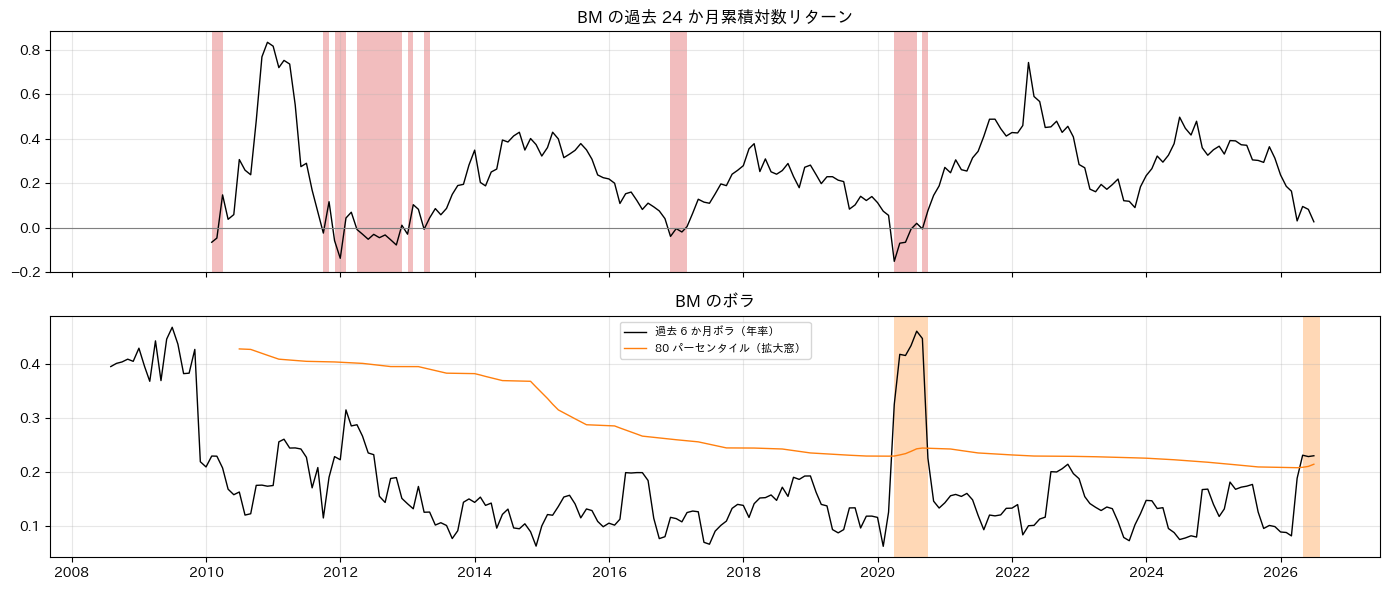

弱気局面の月末: ['2010-01', '2010-02', '2011-09', '2011-11', '2011-12', '2012-03', '2012-04', '2012-05', '2012-06', '2012-07', '2012-08', '2012-09', '2012-10', '2012-12', '2013-03', '2016-11', '2016-12', '2017-01', '2020-03', '2020-04', '2020-05', '2020-06', '2020-08']
高ボラ局面の月末: ['2020-03', '2020-04', '2020-05', '2020-06', '2020-07', '2020-08', '2026-04', '2026-05', '2026-06']


In [2]:
cum24 = np.log1p(bmr).rolling(24, min_periods=24).sum()
vol6 = bmr.rolling(6, min_periods=6).std() * np.sqrt(12)
thr = (
    bmr.rolling(6, min_periods=6).std().expanding(min_periods=24).quantile(0.8)
) * np.sqrt(12)

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(cum24.index, cum24, color="k", linewidth=1)
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_title("BM の過去 24 か月累積対数リターン")
axes[1].plot(vol6.index, vol6, color="k", linewidth=1, label="過去 6 か月ボラ（年率）")
axes[1].plot(
    thr.index, thr, color="C1", linewidth=1, label="80 パーセンタイル（拡大窓）"
)
axes[1].legend(fontsize=8)
axes[1].set_title("BM のボラ")
for ax, st, c in [(axes[0], bear, "C3"), (axes[1], hivol, "C1")]:
    for d in st.index[st]:
        ax.axvspan(d, d + pd.offsets.MonthEnd(1), color=c, alpha=0.3, linewidth=0)
plt.tight_layout()
plt.show()
print("弱気局面の月末:", [d.strftime("%Y-%m") for d in bear.index[bear]])
print("高ボラ局面の月末:", [d.strftime("%Y-%m") for d in hivol.index[hivol]])

## 2. 仮説の検証: スリーブは弱気局面で負けるか

各スリーブと残差モメンタムの Q5−Q1（等ウェイト、drtn、月次）を、判定（前月末）と当月の市場の上げ下げで分けた。
予測 1 は「弱気局面で `sleeve_b` の平均が下がる」、予測 2 は「弱気局面 × 上昇月で負け、弱気局面 × 下落月で勝つ」。

In [3]:
comp_reports = {
    n: compute_alpha_report(
        n,
        s,
        univ,
        bm,
        returns,
        n_quantiles=N_QUANTILES,
        cw_max_weight=CW_MAX_WEIGHT,
        burn_in=BURN_IN,
    )
    for n, s in components.items()
}
mkt = bmr.rename("mkt")
state_ret = bear.shift(1, fill_value=False).rename(
    "bear"
)  # 前月末の判定 → 当月のリターン
rows = {}
for n, rep in comp_reports.items():
    sp = rep.series["spread"]["drtn"].rename("sp")
    df = pd.concat([sp, state_ret, mkt], axis=1).dropna()
    df["bear"] = df["bear"].astype(bool)
    df["up"] = df["mkt"] > 0
    g = df.groupby("bear")["sp"]
    b, nb = df.loc[df["bear"], "sp"], df.loc[~df["bear"], "sp"]
    se = np.sqrt(b.var() / len(b) + nb.var() / len(nb))
    rows[n] = {
        "平常時": nb.mean(),
        "弱気局面": b.mean(),
        "差の t 値": (b.mean() - nb.mean()) / se,
        "弱気 × 上昇月": df.loc[df["bear"] & df["up"], "sp"].mean(),
        "弱気 × 下落月": df.loc[df["bear"] & ~df["up"], "sp"].mean(),
        "平常 × 上昇月": df.loc[~df["bear"] & df["up"], "sp"].mean(),
        "平常 × 下落月": df.loc[~df["bear"] & ~df["up"], "sp"].mean(),
        "弱気の月数": len(b),
    }
print("Q5−Q1 の月平均（drtn）")
display(pd.DataFrame(rows).T.round(4))

Q5−Q1 の月平均（drtn）


,平常時,弱気局面,差の t 値,弱気 × 上昇月,弱気 × 下落月,平常 × 上昇月,平常 × 下落月,弱気の月数
sleeve_a,0.0127,0.0065,-0.6569,-0.0061,0.0353,0.0067,0.0221,23.0
sleeve_b,0.0111,-0.0098,-1.3197,-0.0284,0.0327,0.0025,0.0248,23.0
sleeve_d,0.0087,0.0042,-0.6664,-0.0047,0.0245,0.0029,0.0179,23.0
resid_mom,0.0049,0.0070,0.2324,0.0032,0.0155,-0.0010,0.0141,23.0


In [4]:
print("弱気局面の各月: スリーブ別の Q5−Q1 と市場リターン（drtn、リターンの月で表示）")
months = state_ret.index[state_ret.astype(bool)]
tbl = pd.DataFrame(
    {n: rep.series["spread"]["drtn"] for n, rep in comp_reports.items()}
).reindex(months)
tbl["市場"] = mkt.reindex(months)
display(tbl.round(3))

弱気局面の各月: スリーブ別の Q5−Q1 と市場リターン（drtn、リターンの月で表示）


,sleeve_a,sleeve_b,sleeve_d,resid_mom,市場
2010-02-28,0.007,0.013,0.039,0.045,0.012
2010-03-31,0.035,0.053,0.008,0.062,0.064
2011-10-31,-0.015,-0.036,0.026,0.012,0.079
2011-12-31,0.022,0.036,0.030,0.035,-0.044
2012-01-31,-0.109,-0.249,-0.051,-0.098,0.126
2012-04-30,0.034,0.026,0.011,0.019,-0.014
2012-05-31,0.072,0.069,0.031,0.009,-0.058
2012-06-30,-0.049,-0.082,-0.019,-0.036,0.068
2012-07-31,0.042,0.042,0.033,0.010,-0.008
2012-08-31,0.086,0.040,0.054,0.018,0.011


## 3. 合成スコアの評価

Q5（等ウェイトの BM 超過）→ IC → Q5−Q1 の順。通常月は `comp_ew` と同一なので、差は切り替えた月だけから生じる。

In [5]:
reports = {}
for n, s in scores.items():
    reports[n] = compute_alpha_report(
        n,
        s,
        univ,
        bm,
        returns,
        n_quantiles=N_QUANTILES,
        cw_max_weight=CW_MAX_WEIGHT,
        tax_schedule=schedule,
        cost_buy=COST_BUY,
        cost_sell=COST_SELL,
        burn_in=BURN_IN,
        tax_kind="drtn",
    )
first = reports["comp_ew"]
ew = first.series["ew_excess"]["drtn"]
print(
    f"最上位 = {first.top}。評価期間 {ew.index.min().date()}〜{ew.index.max().date()}（{len(ew)} か月）"
)

tbl = summary_table(reports)
q5, sp, at = (
    first.label("ew_excess"),
    first.label("spread"),
    first.label("after_tax_excess"),
)
cols = [q5, q5 + " IR", "IC", "ICIR", "IC t", sp, sp + " IR"]
for kind in ["drtn", "srtn"]:
    print(
        f"{kind}（{'配当込みトータルリターン' if kind == 'drtn' else '固有リターン'}）"
    )
    display(tbl[kind][cols].round(3))
print("税控除後（drtn）と回転率")
display(pd.concat([tbl["drtn"][[at, at + " IR"]], tbl["共通"]], axis=1).round(3))

最上位 = Q5。評価期間 2009-02-28〜2026-07-31（210 か月）
drtn（配当込みトータルリターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t,Q5 − Q1,Q5 − Q1 IR
comp_ew,0.130,1.165,0.065,0.482,6.982,0.176,1.152
comp_bear0,0.126,1.124,0.064,0.505,7.312,0.180,1.261
comp_bear_half,0.127,1.136,0.065,0.492,7.126,0.178,1.201
comp_bear_resid,0.130,1.174,0.066,0.518,7.505,0.178,1.220
comp_hivol0,0.130,1.152,0.064,0.484,7.020,0.176,1.177
comp_ad,0.103,0.861,0.053,0.534,7.740,0.157,1.484


srtn（固有リターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t,Q5 − Q1,Q5 − Q1 IR
comp_ew,0.101,1.009,0.039,0.380,5.501,0.117,1.071
comp_bear0,0.098,0.967,0.040,0.402,5.823,0.121,1.164
comp_bear_half,0.098,0.982,0.040,0.390,5.658,0.120,1.118
comp_bear_resid,0.102,1.024,0.041,0.405,5.868,0.120,1.135
comp_hivol0,0.099,0.988,0.039,0.380,5.513,0.116,1.086
comp_ad,0.078,0.780,0.036,0.485,7.023,0.111,1.407


税控除後（drtn）と回転率


指標,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,回転率 EW,回転率 CW,コストドラッグ,税ドラッグ,短期比率
comp_ew,0.085,0.790,4.022,4.169,0.017,0.028,0.809
comp_bear0,0.079,0.737,4.179,4.301,0.017,0.028,0.819
comp_bear_half,0.081,0.759,4.065,4.196,0.017,0.028,0.811
comp_bear_resid,0.084,0.790,4.101,4.232,0.017,0.028,0.814
comp_hivol0,0.083,0.772,4.056,4.189,0.017,0.028,0.811
comp_ad,0.056,0.484,4.444,4.703,0.018,0.028,0.887


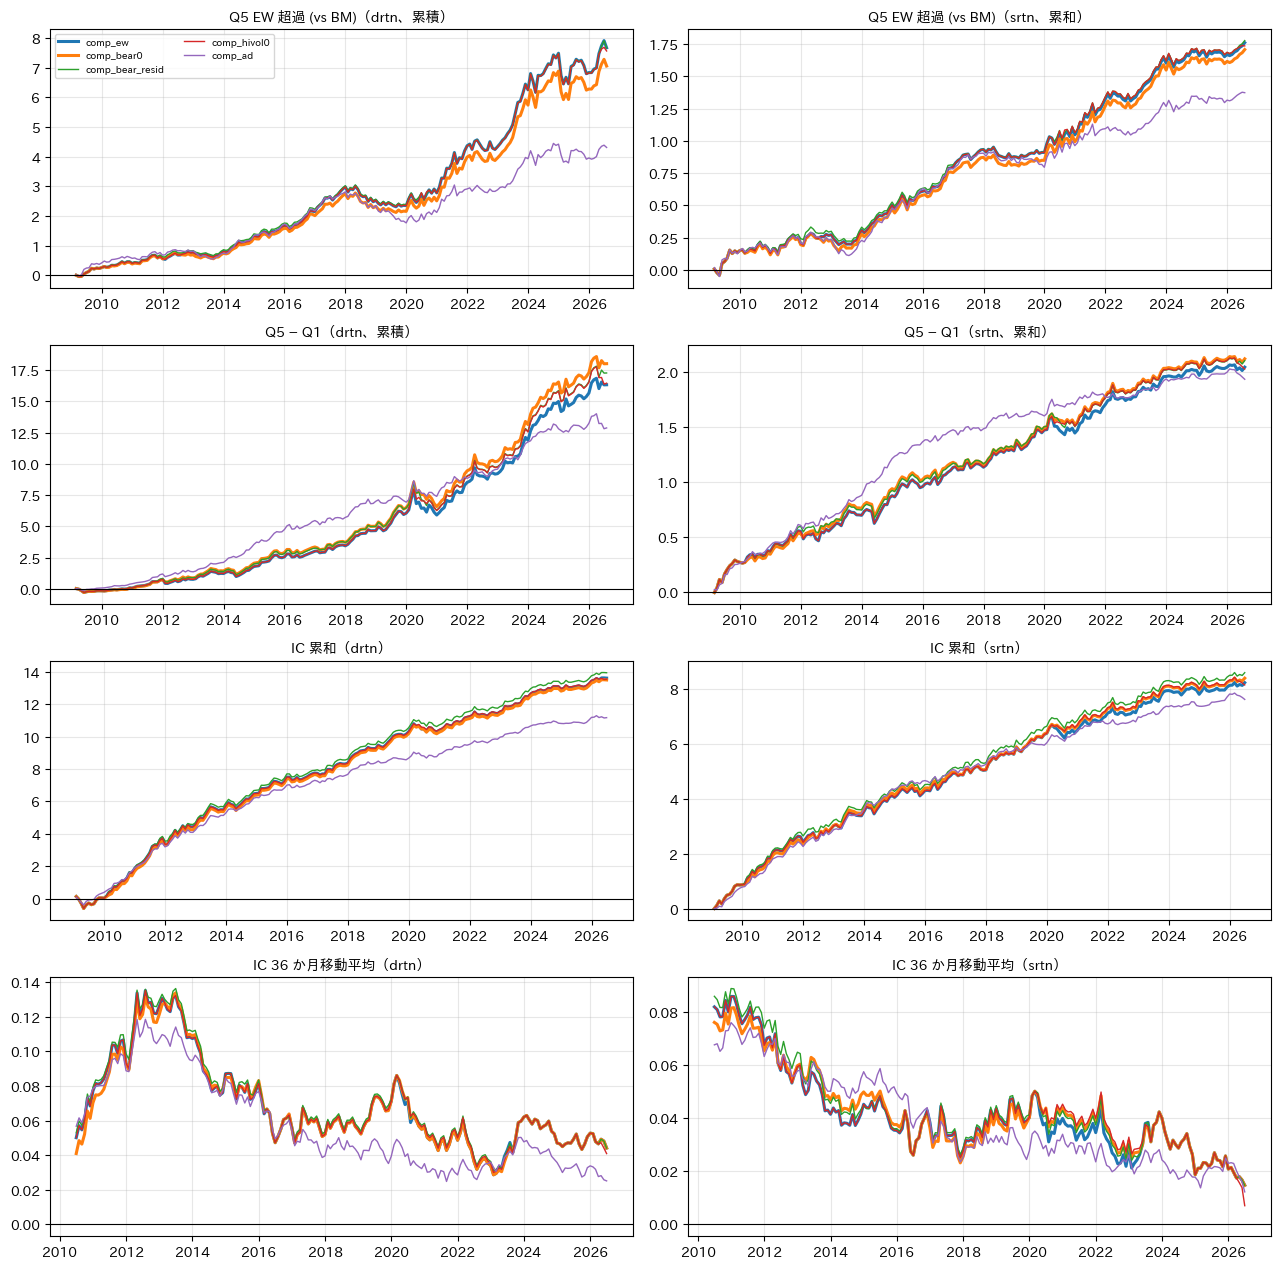

In [6]:
fig = plot_cumulative(
    {
        n: reports[n]
        for n in ["comp_ew", "comp_bear0", "comp_bear_resid", "comp_hivol0", "comp_ad"]
    },
    metrics=("ew_excess", "ic", "spread"),
    highlight=("comp_ew", "comp_bear0"),
)
plt.show()

### 期間別と、切り替えた月だけの比較（drtn）

期間別は年率。切り替えた月だけの比較は、`comp_ew` との月次差の平均（月次）と t 値。

In [7]:
periods = {
    "2009–2017": ("2009-01-01", "2017-12-31"),
    "2018/05–2019/08": ("2018-05-01", "2019-08-31"),
    "2020/04–12": ("2020-04-01", "2020-12-31"),
    "2021–2026": ("2021-01-01", "2026-12-31"),
}
rows = {}
for n, rep in reports.items():
    r = {}
    for p, (a, b) in periods.items():
        r[(p, "Q5 超過")] = rep.series["ew_excess"]["drtn"].loc[a:b].mean() * 12
        r[(p, "IC")] = rep.series["ic"]["drtn"].loc[a:b].mean()
        r[(p, "Q5−Q1")] = rep.series["spread"]["drtn"].loc[a:b].mean() * 12
    rows[n] = r
display(pd.DataFrame(rows).T.round(3))

states_ret = {
    "bear": bear.shift(1, fill_value=False),
    "hivol": hivol.shift(1, fill_value=False),
}
use = {
    "comp_bear0": "bear",
    "comp_bear_half": "bear",
    "comp_bear_resid": "bear",
    "comp_hivol0": "hivol",
}
rows = {}
for n, st in use.items():
    m = states_ret[st]
    r = {}
    for metric, label in [("ew_excess", "Q5 超過"), ("ic", "IC"), ("spread", "Q5−Q1")]:
        d = (
            reports[n].series[metric]["drtn"]
            - reports["comp_ew"].series[metric]["drtn"]
        ).dropna()
        d = d[m.reindex(d.index).fillna(False).astype(bool)]
        r[(label, "差の月平均")] = d.mean()
        r[(label, "t")] = d.mean() / d.std() * np.sqrt(len(d)) if len(d) > 1 else np.nan
    r[("", "月数")] = len(d)
    rows[n] = r
print("切り替えた月だけ: comp_ew との差")
display(pd.DataFrame(rows).T.round(4))

2009–2017               2018/05–2019/08               2020/04–12               2021–2026              
                    Q5 超過     IC  Q5−Q1           Q5 超過     IC  Q5−Q1      Q5 超過     IC  Q5−Q1     Q5 超過     IC  Q5−Q1
comp_ew             0.161  0.077  0.184          -0.139  0.072  0.220      0.092 -0.027 -0.326     0.158  0.049  0.171
comp_bear0          0.154  0.076  0.189          -0.139  0.072  0.220      0.074 -0.034 -0.294     0.158  0.049  0.171
comp_bear_half      0.157  0.077  0.191          -0.139  0.072  0.220      0.051 -0.029 -0.355     0.158  0.049  0.171
comp_bear_resid     0.162  0.080  0.189          -0.139  0.072  0.220      0.077 -0.025 -0.340     0.158  0.049  0.171
comp_hivol0         0.161  0.077  0.184          -0.139  0.072  0.220      0.091 -0.029 -0.271     0.156  0.047  0.163
comp_ad             0.158  0.071  0.222          -0.194  0.035  0.084      0.121 -0.000 -0.178     0.102  0.034  0.093

切り替えた月だけ: comp_ew との差


Q5 超過              IC           Q5−Q1              
                  差の月平均       t   差の月平均       t   差の月平均       t    月数
comp_bear0      -0.0032 -1.1117 -0.0038 -0.3123  0.0028  0.5100  23.0
comp_bear_half  -0.0026 -1.5014 -0.0005 -0.1187  0.0018  0.5705  23.0
comp_bear_resid -0.0001 -0.0515  0.0105  1.1221  0.0015  0.3584  23.0
comp_hivol0     -0.0030 -0.6380 -0.0068 -0.3767 -0.0008 -0.0762   8.0

## 4. 判定期間への感度（過剰適合のチェック）

弱気局面の判定期間を 12・24・36 か月に変えて `comp_bear0` を作り直す（税なし）。判定期間によって結論が変わるなら、
24 か月の結果はたまたまの可能性が高い。

In [8]:
base = weighted_blend(sleeves, {s: 1.0 for s in SLEEVES})
alt = weighted_blend(sleeves, {"sleeve_a": 1.0, "sleeve_d": 1.0})
ref = compute_alpha_report(
    "comp_ew",
    scores["comp_ew"],
    univ,
    bm,
    returns,
    n_quantiles=N_QUANTILES,
    cw_max_weight=CW_MAX_WEIGHT,
    burn_in=BURN_IN,
)
rows = {}
for w in [12, 24, 36]:
    st = bear_state(bmr, w)
    cond = pd.DataFrame(
        np.repeat(st.to_numpy()[:, None], base.shape[1], axis=1),
        index=base.index,
        columns=base.columns,
    )
    sc = alt.where(cond, base).where(univ.notna())
    rep = compute_alpha_report(
        f"bear{w}",
        sc,
        univ,
        bm,
        returns,
        n_quantiles=N_QUANTILES,
        cw_max_weight=CW_MAX_WEIGHT,
        burn_in=BURN_IN,
    )
    r = {"切り替え月数": int(st.loc["2009":].sum())}
    for metric, label in [("ew_excess", "Q5 超過"), ("ic", "IC"), ("spread", "Q5−Q1")]:
        d = (rep.series[metric]["drtn"] - ref.series[metric]["drtn"]).dropna()
        scale = 1 if metric == "ic" else 12
        r[(label, "全期間の差（年率）")] = d.mean() * scale
        r[(label, "2020/04–12 の差")] = (
            d.loc["2020-04":"2020-12"].sum()
            if metric != "ic"
            else d.loc["2020-04":"2020-12"].mean()
        )
    rows[f"{w} か月"] = r
display(pd.DataFrame(rows).T.round(4))

,切り替え月数,"(Q5 超過, 全期間の差（年率）)","(Q5 超過, 2020/04–12 の差)","(IC, 全期間の差（年率）)","(IC, 2020/04–12 の差)","(Q5−Q1, 全期間の差（年率）)","(Q5−Q1, 2020/04–12 の差)"
12 か月,43.0,0.0058,0.0060,-0.0005,0.0025,0.0181,0.0666
24 か月,23.0,-0.0042,-0.0132,-0.0005,-0.0069,0.0037,0.0236
36 か月,2.0,0.0015,0.0021,0.0006,0.0000,0.0058,0.0386


## 5. 所見

**結論: 仮説の方向は合っていたが、弱気局面でモメンタムを外しても合成スコアは改善しない。2020 年の負けの大半は避けられず、ロングオンリーの Q5 ではむしろわずかに悪化する。**

1. **予測 1・2（スリーブ単位）は方向として成立**: `sleeve_b` の Q5−Q1 は平常時 +1.11%/月に対し、弱気局面は −0.98%/月（差の t = −1.3、23 か月）。
   弱気局面 × 上昇月は −2.84%、弱気局面 × 下落月は +3.27% で、Daniel–Moskowitz の非対称が出ている（平常時 × 上昇月は +0.25%）。
   ただしサンプルが小さく、有意とは言えない。
2. **負けはモメンタムに限らない**: 弱気局面ではリビジョン（`sleeve_a`、+1.27% → +0.65%）と規律（`sleeve_d`、+0.87% → +0.42%）も落ち、
   上昇月に負ける形も同じ（2012-01、2020-04、2020-06 は 3 スリーブとも負け）。反発局面の負けは「低品質・高ベータ株の反発」による、シグナル全体の負けだった。
   例外は残差モメンタムで、弱気局面でも落ちない（+0.49% → +0.70%）。ベータを除いたモメンタムはクラッシュしない、という理論どおり。
3. **合成スコア（予測 3）は不成立**: `comp_bear0` は Q5 超過 12.6%（`comp_ew` 13.0%）、IC 0.064（0.065）、Q5−Q1 18.0%（17.6%）、税控除後 7.9%（8.5%）。
   切り替えた 23 か月だけで見ても、Q5 超過の差は −0.32%/月（t = −1.1）。2020-04〜12 の Q5−Q1 は −32.6% → −29.4% と少し改善するが、Q5 超過は 9.2% → 7.4% と悪化した。
   - モメンタムのクラッシュは主にショート側（反発した負け組、2020-04 の Q1 は +25.8%）で起きる。ロングオンリーの Q5 は負け組を持たないので、外しても得るものが小さい
   - 判定は 2020-11 のワクチン報道によるモメンタムの反転（GEMLT の MOMENTUM −3.9%）を捉えられない（その時点では過去 24 か月がプラスに戻っていた）
4. **判定期間に頑健でない**: 全期間の Q5 超過の差は、12 か月 +0.6%、24 か月 −0.4%、36 か月 +0.2%（切り替えは 2 か月だけ）で符号が定まらない。
   高ボラ判定（`comp_hivol0`）もほぼ `comp_ew` と同じ。
5. **常に外すのは悪い**: `comp_ad` は Q5 超過 10.3%（−2.7%）、2018〜19 年の窓の Q5−Q1 は 22.0% → 8.4%、2021 年以降は 17.1% → 9.3%。モメンタムは平常時の主力で、条件付きにする意味自体はある。
6. **残差モメンタムへの置き換え（`comp_bear_resid`）が最もまし**: Q5 超過 13.0%、IC 0.066（ICIR 0.518 vs 0.482）、税控除後 8.4% で `comp_ew` と同等以上。切り替え月の IC 差は +0.011（t = 1.1）。有意ではない。

**含意と次の仮説**

- 2020 年の負けの原因は「モメンタムのクラッシュ」より広く、「弱気相場の後の高ベータ・低品質株の反発」に合成スコア全体が逆張りしていたこと。
  03 のファクター分解でも、2020-04〜12 の Q5 − BM は BETA −2.8%、LIQUIDTY −3.0% を負っていた。
- 手当ての候補は、スリーブを外すことではなく**弱気局面でのベータ・流動性エクスポージャーの中立化**（bax の制約、またはスコアを BETA・LIQUIDTY に対して残差化）。
  ロングオンリーで効くのはこちらのはず。
- 残差モメンタムは弱気局面で崩れない性質が確認できた。`sleeve_b` に常時ブレンドする案は、別途（2021 年以降の弱さも含めて）検証する価値がある。
